# 03 Small multiples: which classes break first, and does the SNN break differently?

Per class × corruption × severity, with 95 % intervals. Confidence is compared through AUROC (how well a model's own confidence separates its right from its wrong answers), because CNN confidence is a softmax probability and SNN confidence is a raw Akida potential. Tests H3, H4, H6, H7.

In [1]:
%matplotlib inline
import os
import sys
import warnings

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")
sys.path.insert(0, ".")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aiv.load import CLASSES, OUTCOMES, data_source, paired, pick
from aiv.stats import wilson
from lab.config import CORRUPTIONS, SEVERITIES

CNN, SNN = pick()
W = paired(CNN, SNN)
COND = [("clean", 0)] + [(c, s) for c in CORRUPTIONS for s in SEVERITIES]
COL = dict(zip(OUTCOMES, ["#d9d9d9", "#d62728", "#1f77b4", "#7f7f7f", "#ff7f0e"]))
print(f"CNN = {CNN} | SNN = {SNN} | data = {data_source()} | rows = {len(W):,}")

CNN = cnn-float | SNN = snn-sim | data = regenerated CIFAR-10-C (not official) | rows = 160,000


## Outcome composition per class × corruption
Stacked share of images per outcome vs severity.

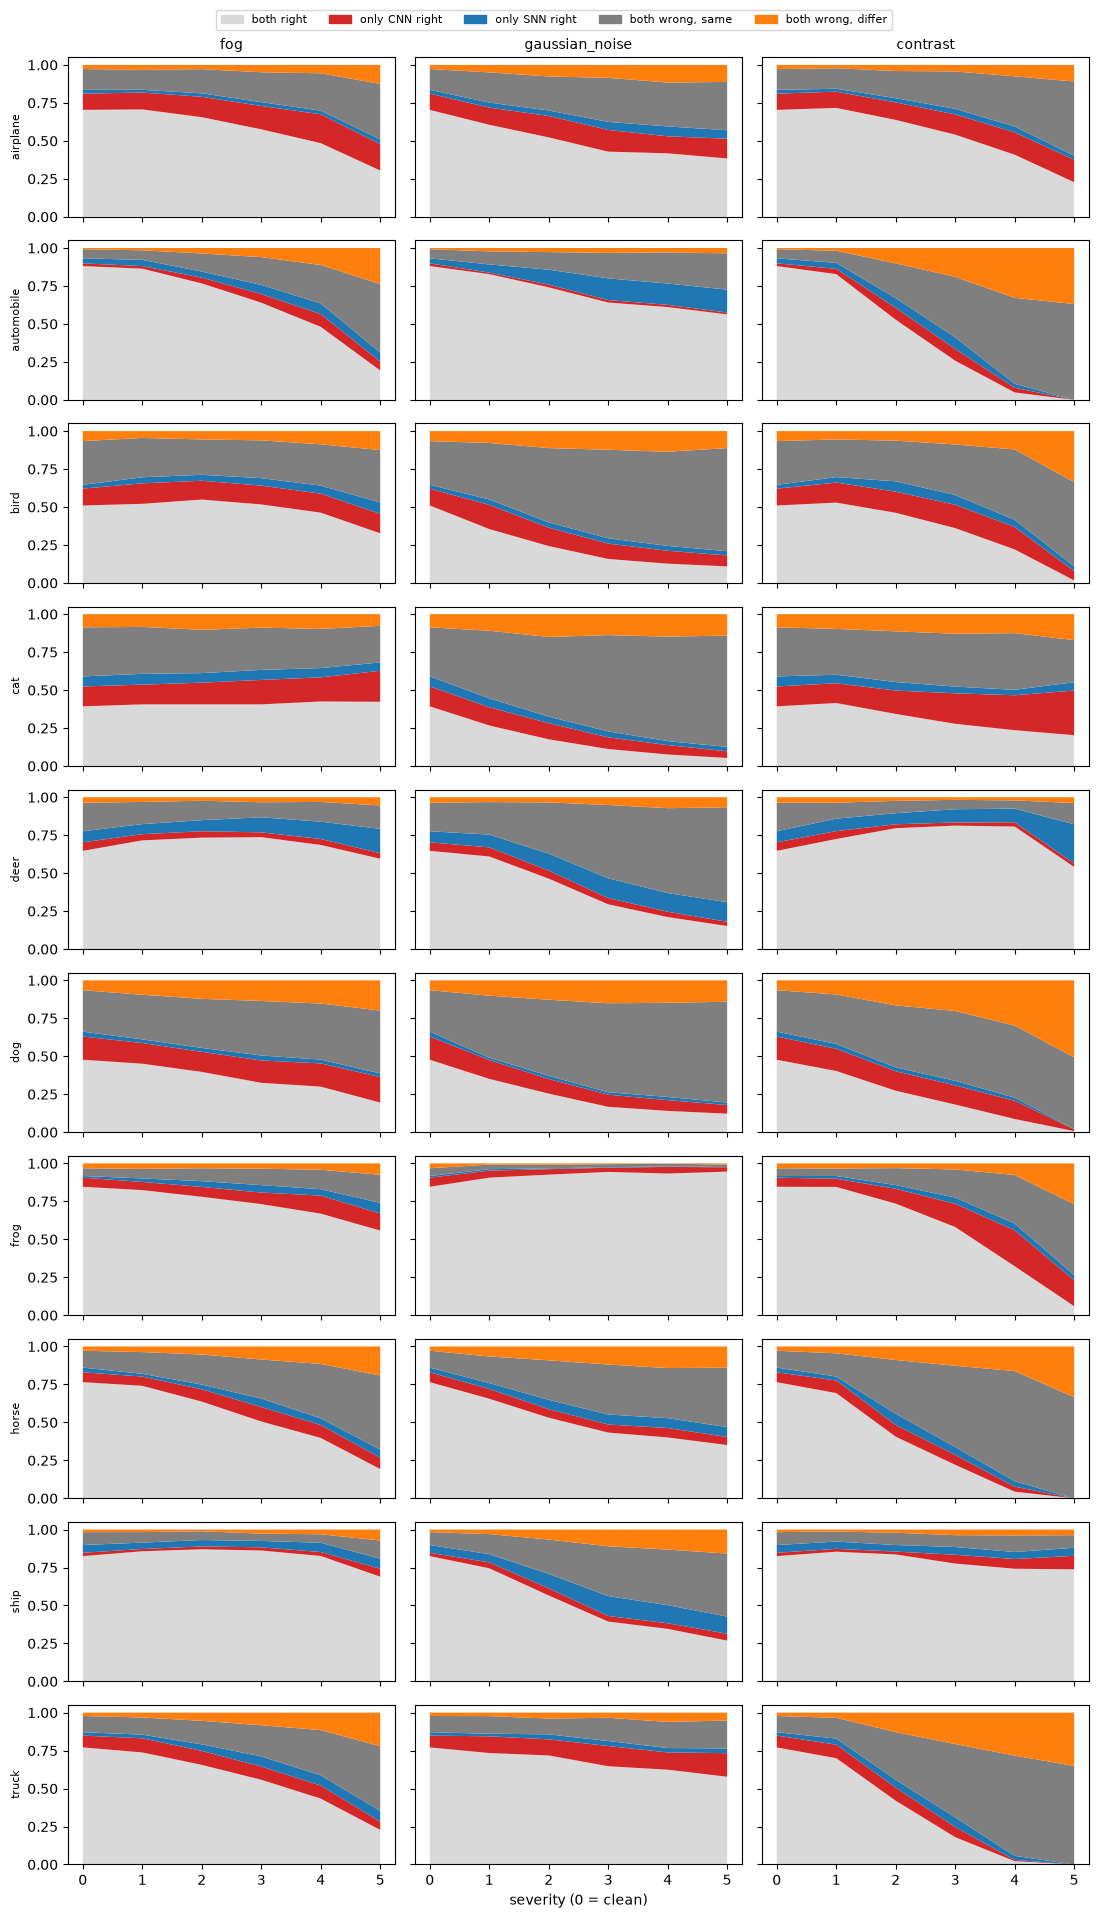

In [3]:
fig, axs = plt.subplots(10, 3, figsize=(11, 19), sharex=True, sharey=True)
for j, corr in enumerate(CORRUPTIONS):
    d = W[W.corruption.isin(["clean", corr])]
    for k in range(10):
        t = (d[d.label == k].groupby("severity").outcome.value_counts(normalize=True)
             .unstack(fill_value=0).reindex(columns=OUTCOMES, fill_value=0))
        axs[k, j].stackplot(t.index, t.T.values, colors=list(COL.values()))
        if j == 0:
            axs[k, j].set_ylabel(CLASSES[k], fontsize=8)
    axs[0, j].set_title(corr, fontsize=10)
axs[-1, 1].set_xlabel("severity (0 = clean)")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COL.values()], OUTCOMES, loc="upper center",
           ncol=5, fontsize=8, bbox_to_anchor=(.5, 1.01))
plt.tight_layout()
plt.show()

## Per-class accuracy gap SNN − CNN (paired 95 % CI)
Negative = SNN loses more. One panel per corruption; each class shows severities 1–5 left to right.

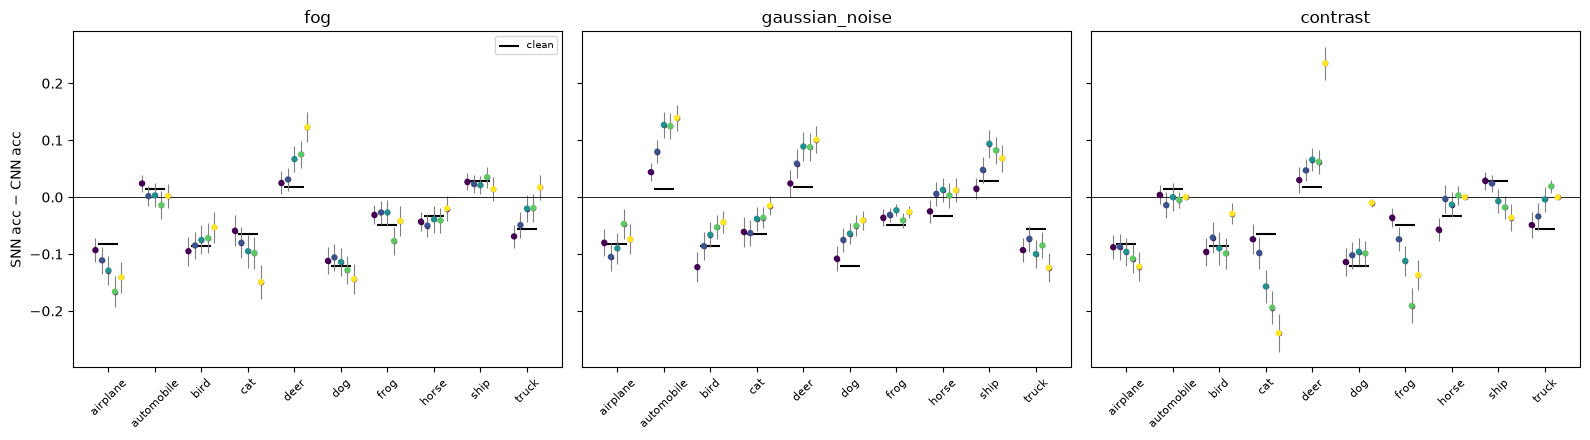

In [4]:
from aiv.stats import paired_diff

rows = []
for (c, s), d in W.groupby(["corruption", "severity"], sort=False):
    for k in range(10):
        dk = d[d.label == k]
        rows.append((c, s, CLASSES[k], *paired_diff(dk.cnn_ok, dk.snn_ok)))
G = pd.DataFrame(rows, columns=["corruption", "severity", "cls", "diff", "lo", "hi", "n"])
fig, axs = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, corr in zip(axs, CORRUPTIONS):
    for k, name in enumerate(CLASSES):
        g = G[(G.corruption == corr) & (G.cls == name)]
        xs = k + (g.severity.values - 3) * .14
        ax.errorbar(xs, g["diff"], yerr=[g["diff"] - g.lo, g.hi - g["diff"]], fmt="o", ms=3,
                    color=plt.cm.viridis((g.severity.values - 1) / 4)[0], ecolor="grey", lw=.8)
        ax.scatter(xs, g["diff"], c=plt.cm.viridis((g.severity.values - 1) / 4), s=12, zorder=3)
    c0 = G[G.corruption == "clean"].set_index("cls")["diff"]
    ax.scatter(range(10), c0.reindex(CLASSES), marker="_", s=200, c="k", label="clean")
    ax.axhline(0, c="k", lw=.6)
    ax.set_title(corr)
    ax.set_xticks(range(10))
    ax.set_xticklabels(CLASSES, rotation=45, fontsize=8)
axs[0].set_ylabel("SNN acc − CNN acc")
axs[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

## Disagreement rate: class × severity, one heatmap per corruption
Cell text = rate; ± = half-width of the 95 % Wilson interval.

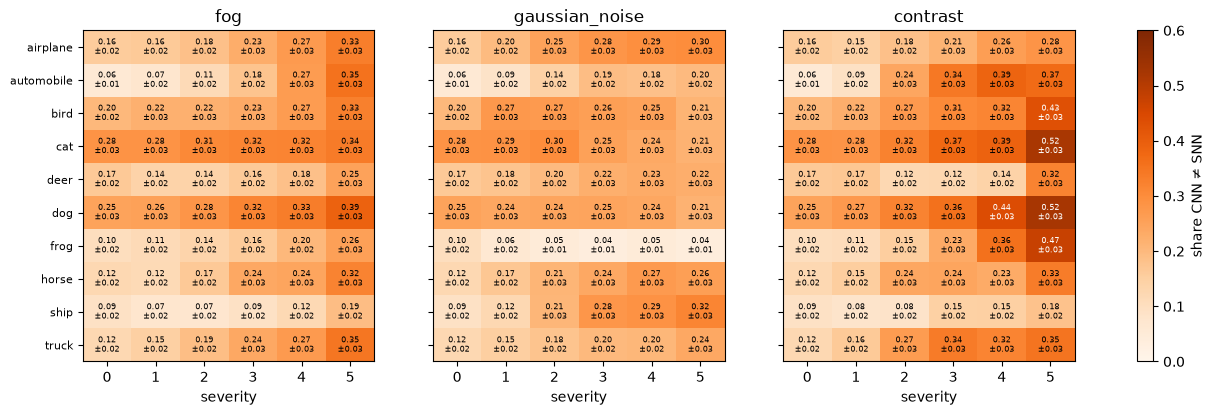

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for ax, corr in zip(axs, CORRUPTIONS):
    d = W[W.corruption.isin(["clean", corr])].assign(dis=lambda x: ~x.agree)
    k = d.pivot_table(index="label", columns="severity", values="dis", aggfunc="sum")
    n = d.pivot_table(index="label", columns="severity", values="dis", aggfunc="size")
    r = k / n
    lo, hi = wilson(k.values, n.values)
    im = ax.imshow(r.values, cmap="Oranges", vmin=0, vmax=.6, aspect="auto")
    for (i, j), v in np.ndenumerate(r.values):
        ax.text(j, i, f"{v:.2f}\n±{(hi[i, j] - lo[i, j]) / 2:.2f}", ha="center", va="center",
                fontsize=5.5, color="w" if v > .4 else "k")
    ax.set_xticks(range(6))
    ax.set_xticklabels(r.columns)
    ax.set_title(corr)
    ax.set_xlabel("severity")
axs[0].set_yticks(range(10))
axs[0].set_yticklabels(CLASSES, fontsize=8)
fig.colorbar(im, ax=axs, label="share CNN ≠ SNN")
plt.show()

## H6: does confidence still separate right from wrong?
AUROC of each model's own confidence for predicting its own correctness (0.5 = useless), 95 % bootstrap interval (200 resamples). Scale-free, so CNN probability and SNN potential are comparable.

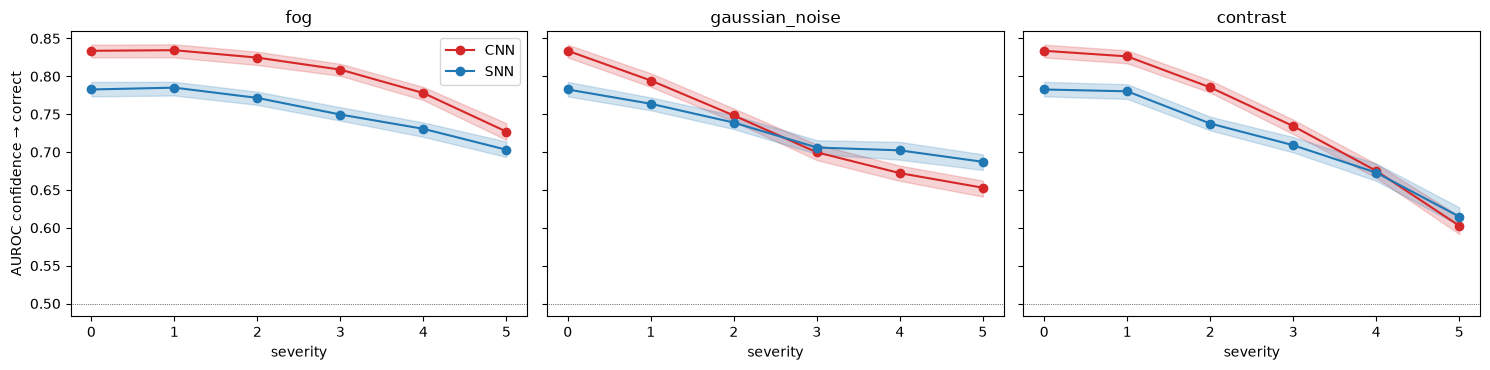

model                      cnn    snn
corruption     severity              
clean          0         0.834  0.783
fog            1         0.835  0.785
               2         0.825  0.772
               3         0.809  0.750
               4         0.778  0.731
               5         0.727  0.703
gaussian_noise 1         0.794  0.764
               2         0.748  0.739
               3         0.700  0.706
               4         0.672  0.702
               5         0.653  0.687
contrast       1         0.826  0.780
               2         0.785  0.738
               3         0.734  0.709
               4         0.675  0.673
               5         0.603  0.615

In [6]:
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(0)
rows = []
for (c, s), d in W.groupby(["corruption", "severity"], sort=False):
    for m in ("cnn", "snn"):
        y, sc = d[f"{m}_ok"].values, d[f"confidence_{m}"].values
        auc = roc_auc_score(y, sc)
        bs = []
        for _ in range(200):
            i = rng.integers(0, len(y), len(y))
            if y[i].min() != y[i].max():
                bs.append(roc_auc_score(y[i], sc[i]))
        rows.append((c, s, m, auc, *np.percentile(bs, [2.5, 97.5])))
A = pd.DataFrame(rows, columns=["corruption", "severity", "model", "auroc", "lo", "hi"])
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, corr in zip(axs, CORRUPTIONS):
    for m, col in (("cnn", "#d62728"), ("snn", "#1f77b4")):
        a = A[(A.model == m) & A.corruption.isin(["clean", corr])].sort_values("severity")
        ax.plot(a.severity, a.auroc, marker="o", color=col, label=m.upper())
        ax.fill_between(a.severity, a.lo, a.hi, color=col, alpha=.2)
    ax.axhline(.5, c="k", lw=.5, ls=":")
    ax.set_title(corr)
    ax.set_xlabel("severity")
axs[0].set_ylabel("AUROC confidence → correct")
axs[0].legend()
plt.tight_layout()
plt.show()
A.round(3).pivot_table(index=["corruption", "severity"], columns="model", values="auroc", sort=False)

## Energy as an attribute (H7)

In [7]:
from lab.config import RESULTS
e = sorted(RESULTS.glob("*/energy.csv"))
print("energy.csv files:", [str(p.relative_to(RESULTS)) for p in e] or "none - lab.evaluate does not "
      "write energy yet, and the simulator reports no power. H7 cannot be tested in this run.")

energy.csv files: none - lab.evaluate does not write energy yet, and the simulator reports no power. H7 cannot be tested in this run.


## Findings (03 small multiples)

Run: `cnn-float` vs `snn-sim`, 10 000 images per condition (about 1000 per class), **regenerated**
CIFAR-10-C. 95 % intervals: paired for gaps, bootstrap (200) for AUROC.

1. **The clean gap is not uniform across classes.** SNN − CNN on clean images: dog −12.1 pp
   [−14.7, −9.5], bird −8.6, airplane −8.2, cat −6.5, truck −5.6. Ship (+2.9) and automobile
   (+1.5) are slightly better for the SNN. Deer +1.7 [−0.5, +3.9] is within noise.
2. **Corruption turns the deer sink into a deer "advantage".** By severity 5 the SNN is ahead
   on deer: contrast +23.5 pp [20.6, 26.4], fog +12.3, noise +10.1. This advantage comes from
   predicting deer for most inputs (01, finding 3), not from seeing deer better. Its mirror image
   is cat −23.9 pp [−27.2, −20.6] and frog −13.7 at contrast 5, and cat −14.9, dog −14.4,
   airplane −14.1 at fog 5.
3. **H3 is only weakly supported.** Overall, contrast widens the gap at severities 3–4 (sev 4:
   −6.3 pp [−7.0, −5.6] vs clean −4.3 [−5.0, −3.7]) but not at 5 (−3.4). Drop from clean at
   sev 4: CNN −36.4 pp, SNN −38.3 pp. The clear SNN-specific contrast effect is the *shift of
   errors* into deer, not a bigger loss in accuracy. The 4-bit mechanism is untested.
4. **H4 is refuted: the SNN degrades *less* under noise.** The gap closes from −4.3 pp to
   −0.6 [−1.3, +0.1] at severity 3 and −0.0 [−0.7, +0.7] at 5. Drop from clean: CNN −34.7 pp,
   SNN −30.4 pp. From severity 3 the two models are equally accurate on noisy images.
5. **Disagreement is lowest where both models share a sink.** Frog under noise has at most 0.06 (0.04 at severity 3–5),
   because both send noisy images to frog. Cat and dog are highest under contrast 5 (0.52 each,
   ±0.03).
6. **H6 holds on clean, fog and contrast, and fails under strong noise.** The SNN's confidence
   separates right from wrong less well on clean images (AUROC 0.783 [0.774, 0.793] vs CNN
   0.834 [0.825, 0.842]) and at fog 5 (0.703 vs 0.727). They are equal at contrast 4–5. Under
   noise severity 5 the SNN is *better* (0.687 [0.677, 0.698] vs 0.653 [0.643, 0.665]).
7. **H7 cannot be tested.** There is no energy data: the simulator reports only fps, and
   `lab.evaluate` writes no `energy.csv`.
